In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import umap
from sklearn.decomposition import PCA

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Locate the repo from the current directory, so the notebook runs from anywhere.
HERE = Path.cwd()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError(f"Start the notebook inside the repo: no pyproject.toml above {HERE}.")
DATA_DIR = ROOT / "data"

In [3]:
sns.set_theme(style="white", context="notebook")

In [6]:
df = pd.read_csv(DATA_DIR / "arxiv_papers_preprocessed.csv")
X_v1 = np.load(DATA_DIR / "arxiv_embeddings_v1.npy")
X_v2 = np.load(DATA_DIR / "arxiv_embeddings_v2.npy")

assert len(df) == len(X_v1), "metadata and embeddings are out of sync"
assert len(df) == len(X_v2), "metadata and embeddings are out of sync"

print("Papers:", len(df), "| Embeddings:", X_v1.shape)

Papers: 2000 | Embeddings: (2000, 768)


In [7]:
df.head()

,request_id,retrieved_at,domain,arxiv_id,title,summary,authors,primary_category,categories,published,updated,abs_url,pdf_url,text,text_clean
0,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40655v1,Elucidating the Design Space of LM Data Attrib...,Data attribution methods for Language Models (...,Steven Yu; Sheng-Yu Wang; Kimia Hamidieh; Anto...,cs.CL,cs.CL,2026-10-29 17:59:53+00:00,2026-10-29 17:59:53+00:00,http://arxiv.org/abs/2610.40655v1,https://arxiv.org/pdf/2610.40655v1,Elucidating the Design Space of LM Data Attrib...,Elucidating the Design Space of LM Data Attrib...
1,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40654v1,Propose-Filter-Release: Scaling Noise to Typic...,An estimator can be accurate and stable on typ...,Moshe Shenfeld; Eliad Tsfadia; Katrina Ligett,cs.LG,cs.LG,2026-10-29 17:59:49+00:00,2026-10-29 17:59:49+00:00,http://arxiv.org/abs/2610.40654v1,https://arxiv.org/pdf/2610.40654v1,Propose-Filter-Release: Scaling Noise to Typic...,Propose-Filter-Release: Scaling Noise to Typic...
2,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40653v1,Micro-Edits: Computational Support for Fine-Sc...,"In film editing, every frame matters. While ma...",Nhan Tran; Hijung Valentina Shin; Abe Davis; M...,cs.HC,cs.HC; cs.CV,2026-10-29 17:59:49+00:00,2026-10-29 17:59:49+00:00,http://arxiv.org/abs/2610.40653v1,https://arxiv.org/pdf/2610.40653v1,Micro-Edits: Computational Support for Fine-Sc...,Micro-Edits: Computational Support for Fine-Sc...
3,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40649v1,Rethinking Neural Thickets Without Weight Pert...,The Neural Thickets hypothesis posits that pre...,Nicolas Dufour; Elouan Gardès; Amil Dravid; Pa...,cs.LG,cs.LG; cs.AI; cs.CV,2026-10-29 17:59:29+00:00,2026-10-29 17:59:29+00:00,http://arxiv.org/abs/2610.40649v1,https://arxiv.org/pdf/2610.40649v1,Rethinking Neural Thickets Without Weight Pert...,Rethinking Neural Thickets Without Weight Pert...
4,https://arxiv.org/api/Nn9ZAl7r/hPtw2SqI662/Ri9DWc,2026-10-30 05:02:17+00:00,cs,2610.40647v1,"Read, Allocate, Route: Role-Coupled Tokenizati...",Pixel-space generative Transformers typically ...,Jiongfan Yang; Weichen Fan; Haiwen Diao; Zhong...,cs.CV,cs.CV; cs.AI; cs.LG; cs.NE,2026-10-29 17:59:21+00:00,2026-10-29 17:59:21+00:00,http://arxiv.org/abs/2610.40647v1,https://arxiv.org/pdf/2610.40647v1,"Read, Allocate, Route: Role-Coupled Tokenizati...","Read, Allocate, Route: Role-Coupled Tokenizati..."


In [8]:
def plot_category_counts(series, title):
    """Horizontal bars for how often each value occurs, rarest at the bottom."""
    counts = series.value_counts()
    share = counts / len(series) * 100
    names = [str(name) for name in counts.index]

    _, ax = plt.subplots(figsize=(8, max(3, 0.22 * len(counts))))
    ax.barh(names[::-1], counts.values[::-1], color="#4c72b0")
    ax.bar_label(
        ax.containers[0],
        labels=[f"{pct:.1f}%" for pct in share.values[::-1]],
        padding=2,
        fontsize=7,
    )

    ax.set_title(title, loc="left")
    ax.set_xlabel("Number of papers")
    ax.tick_params(labelsize=6 if len(counts) > 20 else 10)
    ax.margins(x=0.12)
    sns.despine()
    plt.tight_layout()
    plt.show()

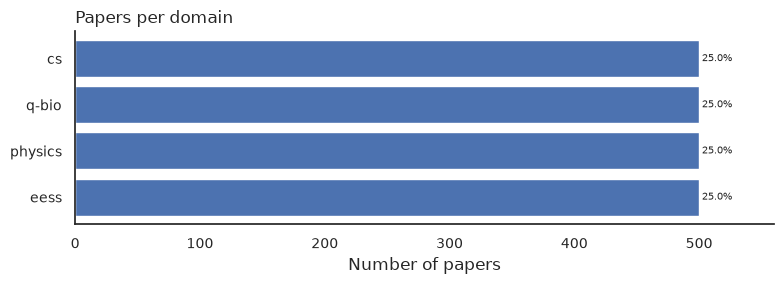

In [9]:
plot_category_counts(df["domain"], "Papers per domain")

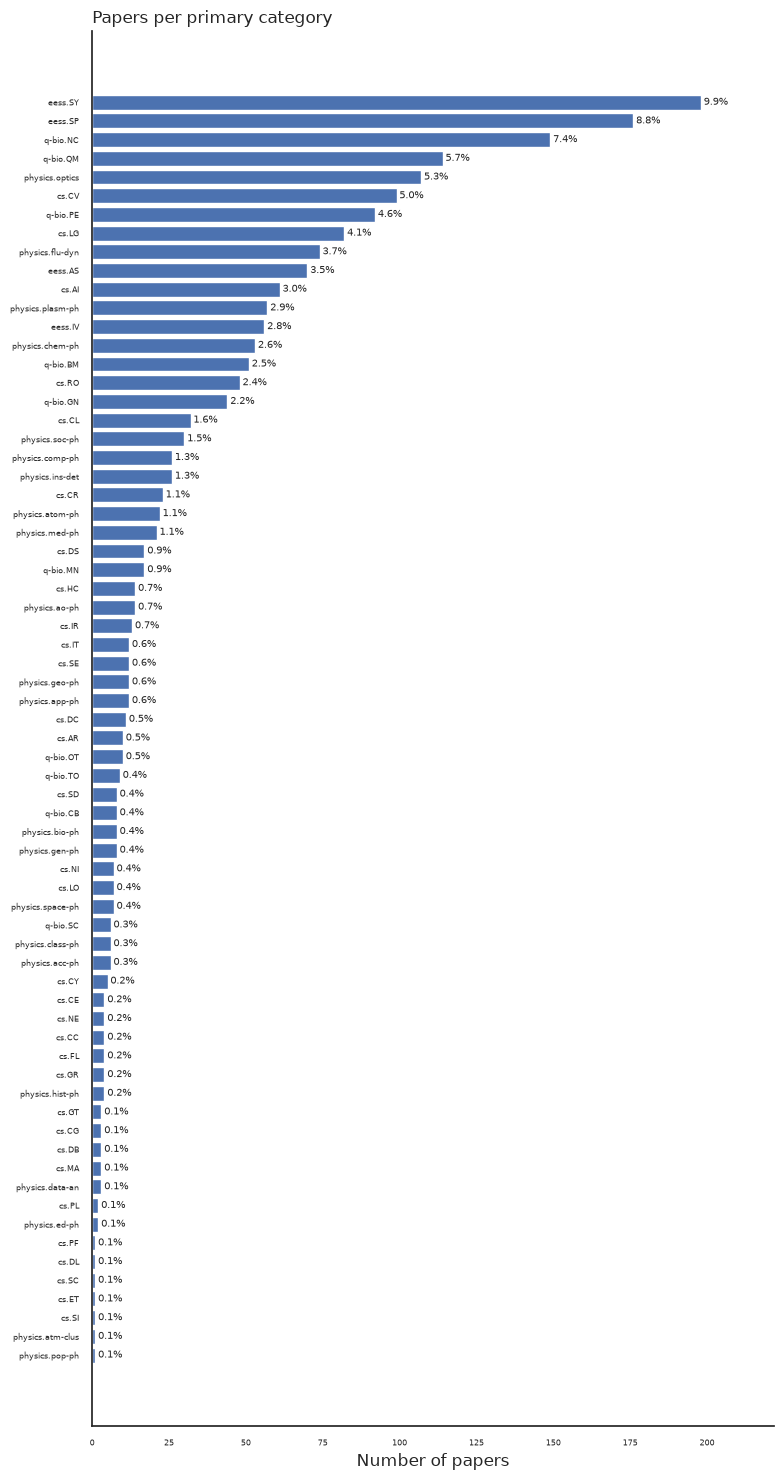

In [10]:
plot_category_counts(df["primary_category"], "Papers per primary category")

In [19]:
pca_v1 = PCA(n_components=2)
X_pca_v1 = pca_v1.fit_transform(X_v1)

In [20]:
print("Explained variance:", pca_v1.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca_v1.explained_variance_ratio_))

Explained variance: [0.07211289 0.04547409]
Cumulative: [0.07211289 0.11758699]


In [21]:
pca_v2 = PCA(n_components=2)
X_pca_v2 = pca_v2.fit_transform(X_v2)

In [22]:
print("Explained variance:", pca_v2.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca_v2.explained_variance_ratio_))

Explained variance: [0.1421455  0.13162509]
Cumulative: [0.1421455  0.27377057]


In [23]:
reducer_v1 = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
X_umap_v1 = reducer_v1.fit_transform(X_v1)

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [24]:
reducer_v2 = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
X_umap_v2 = reducer_v2.fit_transform(X_v2)

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [25]:
reducer_3d_v1 = umap.UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
X_umap_3d_v1 = reducer_3d_v1.fit_transform(X_v1)


/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [26]:
reducer_3d_v2 = umap.UMAP(
    n_components=3,
    n_neighbors=15,
    min_dist=0.0,
    metric="cosine",
    random_state=42,
)
X_umap_3d_v2 = reducer_3d_v2.fit_transform(X_v2)

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [27]:
def plot_embedding_2d(coords, title, xlabel, ylabel):
    """Scatter a 2D projection, one colour per domain. Coordinates are unlabelled."""
    plot_df = (
        df.assign(x=coords[:, 0], y=coords[:, 1])
        .sample(frac=1, random_state=42)
    )

    counts = plot_df["domain"].value_counts()
    plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

    _, ax = plt.subplots(figsize=(10, 7))
    sns.scatterplot(
        data=plot_df,
        x="x", y="y",
        hue="domain_n",
        hue_order=sorted(plot_df["domain_n"].unique()),
        palette="tab10",
        s=8, alpha=0.6, linewidth=0, rasterized=True,
        ax=ax,
    )

    ax.set_title(title, loc="left", fontsize=13)
    ax.set(xlabel=xlabel, ylabel=ylabel, xticks=[], yticks=[])
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1.02, 1), title="Domain", frameon=False)
    sns.despine()
    plt.tight_layout()
    plt.show()


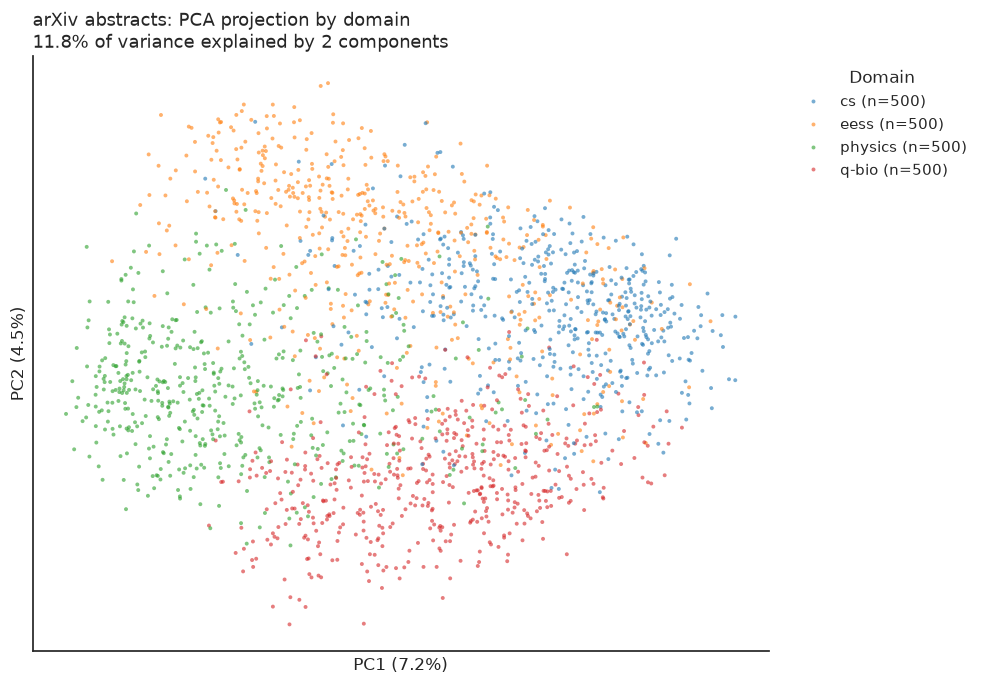

In [28]:
var = pca_v1.explained_variance_ratio_ * 100
plot_embedding_2d(
    X_pca_v1,
    "arXiv abstracts: PCA projection by domain\n"
    f"{var.sum():.1f}% of variance explained by 2 components",
    f"PC1 ({var[0]:.1f}%)",
    f"PC2 ({var[1]:.1f}%)",
)


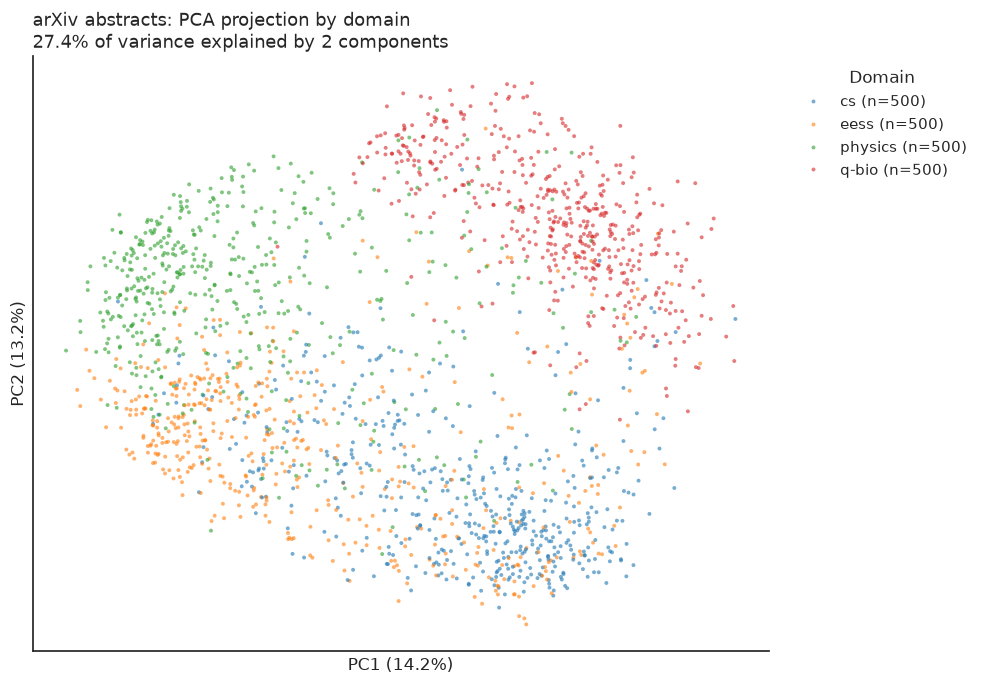

In [29]:
var = pca_v2.explained_variance_ratio_ * 100
plot_embedding_2d(
    X_pca_v2,
    "arXiv abstracts: PCA projection by domain\n"
    f"{var.sum():.1f}% of variance explained by 2 components",
    f"PC1 ({var[0]:.1f}%)",
    f"PC2 ({var[1]:.1f}%)",
)

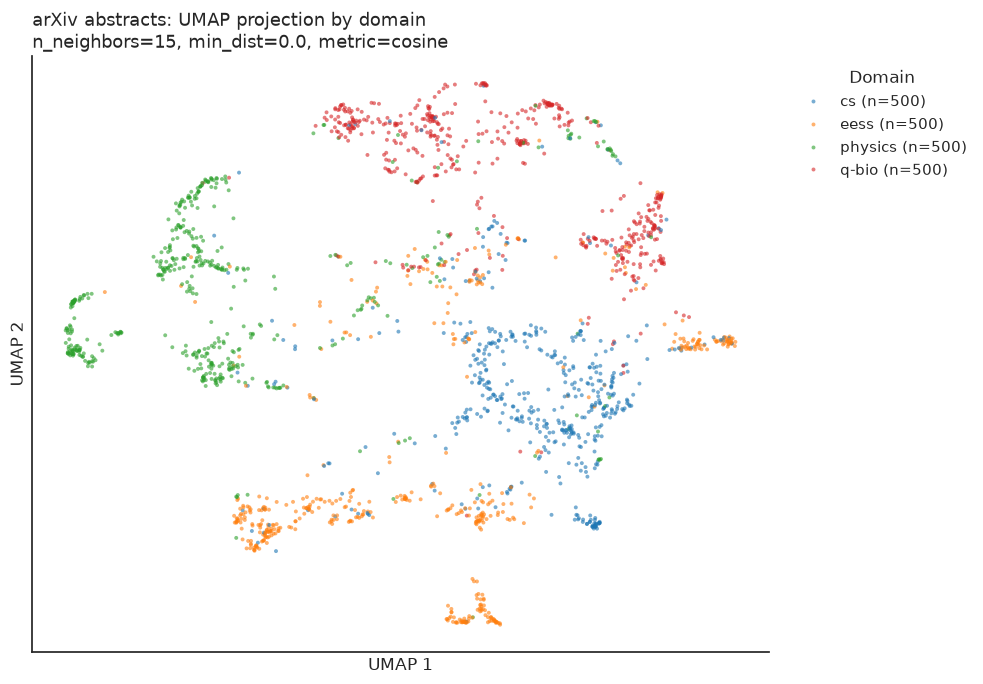

In [30]:
plot_embedding_2d(
    X_umap_v1,
    "arXiv abstracts: UMAP projection by domain\n"
    "n_neighbors=15, min_dist=0.0, metric=cosine",
    "UMAP 1",
    "UMAP 2",
)


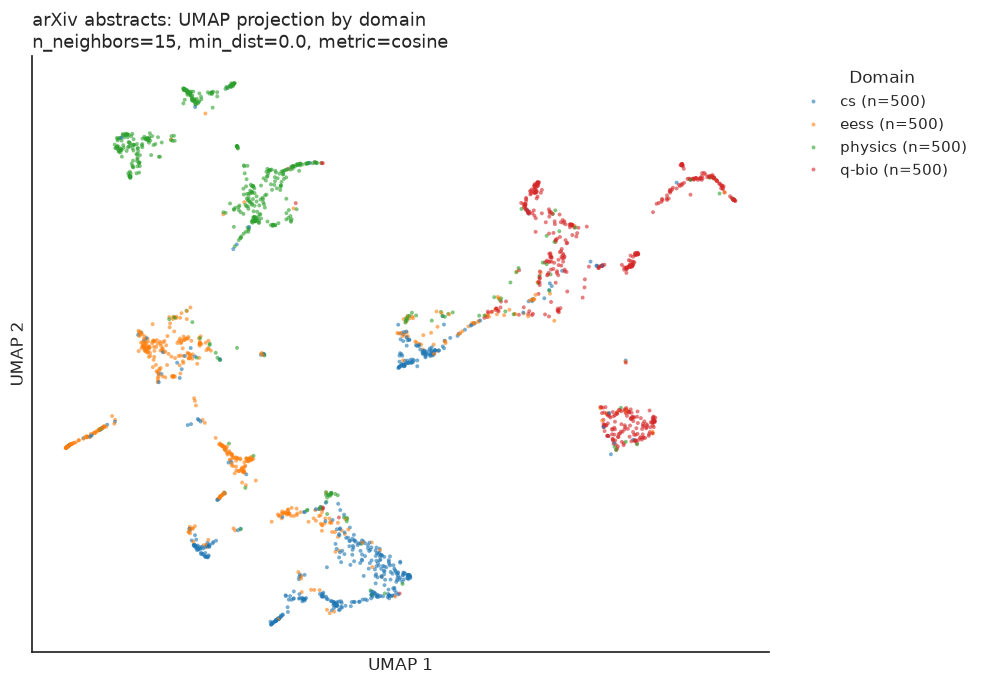

In [31]:
plot_embedding_2d(
    X_umap_v2,
    "arXiv abstracts: UMAP projection by domain\n"
    "n_neighbors=15, min_dist=0.0, metric=cosine",
    "UMAP 1",
    "UMAP 2",
)

In [32]:
plot_df = (
    df.assign(umap_1=X_umap_3d_v1[:, 0], umap_2=X_umap_3d_v1[:, 1], umap_3=X_umap_3d_v1[:, 2])
    .sample(frac=1, random_state=42)
)

counts = plot_df["domain"].value_counts()
plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

fig = px.scatter_3d(
    plot_df,
    x="umap_1", y="umap_2", z="umap_3",
    color="domain_n",
    category_orders={"domain_n": sorted(plot_df["domain_n"].unique())},
    hover_name="title",
    hover_data={"primary_category": True, "umap_1": False, "umap_2": False, "umap_3": False},
    opacity=0.7,
    title="arXiv abstracts: 3D UMAP projection by domain<br>"
          "<sup>n_neighbors=15, min_dist=0.0, metric=cosine</sup>",
    width=950, height=750,
)
fig.update_traces(marker=dict(size=2.5))
fig.update_layout(
    legend_title_text="Domain",
    scene=dict(xaxis_title="UMAP 1", yaxis_title="UMAP 2", zaxis_title="UMAP 3"),
)
fig.show()


In [33]:
plot_df = (
    df.assign(umap_1=X_umap_3d_v2[:, 0], umap_2=X_umap_3d_v2[:, 1], umap_3=X_umap_3d_v2[:, 2])
    .sample(frac=1, random_state=42)
)

counts = plot_df["domain"].value_counts()
plot_df["domain_n"] = plot_df["domain"].map(lambda d: f"{d} (n={counts[d]})")

fig = px.scatter_3d(
    plot_df,
    x="umap_1", y="umap_2", z="umap_3",
    color="domain_n",
    category_orders={"domain_n": sorted(plot_df["domain_n"].unique())},
    hover_name="title",
    hover_data={"primary_category": True, "umap_1": False, "umap_2": False, "umap_3": False},
    opacity=0.7,
    title="arXiv abstracts: 3D UMAP projection by domain<br>"
          "<sup>n_neighbors=15, min_dist=0.0, metric=cosine</sup>",
    width=950, height=750,
)
fig.update_traces(marker=dict(size=2.5))
fig.update_layout(
    legend_title_text="Domain",
    scene=dict(xaxis_title="UMAP 1", yaxis_title="UMAP 2", zaxis_title="UMAP 3"),
)
fig.show()